# Miniproject 2

### Goals for this miniproject
1. Understand how to load and index numpy arrays
2. examine and understand time series data
3. Do simple mathematical operations on numpy arrays
4. Use for loops to perform repeated computations
5. learn how to describe temporal processing of neurons using a spike triggered average (STA)
---
### How to use this notebook during class
- Follow along as we go
- Use your **Cards** to indicate where you're at:
    - A **🟩Green card** means you are caught up with Max and **ready to help your classmates**
    - A **🟥Red card** means you are stuck and need help
- <span style='color:red;'>EXERCISE</span> — work on this problem by yourself, or try with a partner if you get stuck
---


First let's import some libraries we will use today

!pip install _package_name_ 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 0) Load the data

This miniproject uses neuronal spiking data, measured using a multi-electrode array, from guinea pig retinal ganglion cells. You should have these files in your working directory:

`stim_trace.npy`

`spike_binary.npy`

The data are from this paper:

https://journals.plos.org/ploscompbiol/article?id=10.1371/journal.pcbi.1003344


In [2]:
stimulus_intensity = np.load('stim_trace.npy')
spike_binary = np.load('spike_binary.npy')

# 1) Understand the data and the stimulus

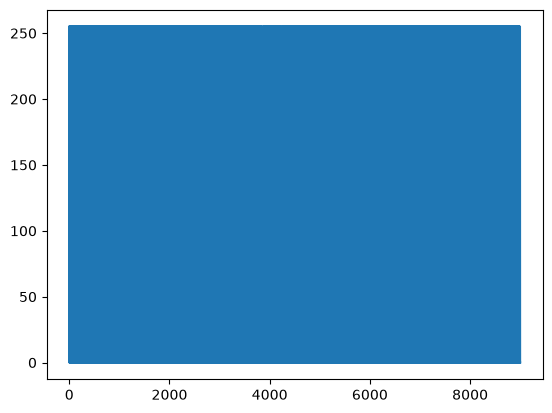

In [3]:
plt.plot(stimulus_intensity)

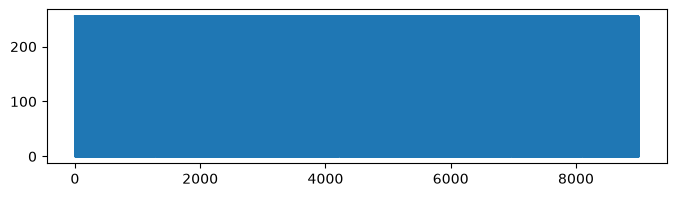

In [4]:
fh, ax = plt.subplots(1,1, figsize=(8,2))
ax.plot(stimulus_intensity)

Text(0.5, 0, 'Frame')

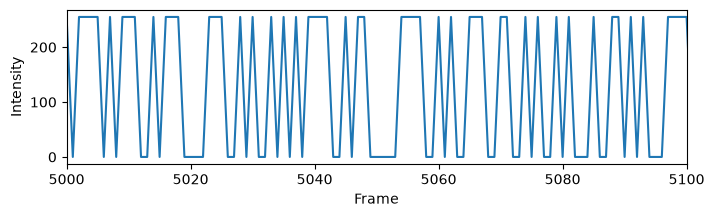

In [6]:
fh, ax = plt.subplots(1, 1, figsize=(8,2))
ax.plot(stimulus_intensity)
ax.set_xlim([5000, 5100])
ax.set_ylabel('Intensity')
ax.set_xlabel('Frame')

Intensity values live in the interval [0, 255]. This is because the stimulus screen represents brightness with 8 bit depth

In [7]:
2 ** 8

256

### <span style='color:red;'>EXERCISE 1</span>: Convert intensity to contrast (5 minutes)
For spike triggered analysis, it is useful to convert stimulus intensity to stimulus contrast

A common definition of contrast is the Weber contrast

C = (I-b) / b

Where c is the contrast, I is the intensity, and b is the background / mean intensity.

First, compute the background (mean) intensity, then use that in the equation for Weber contrast to make a new array, called `stimulus_contrast`

Then plot it, like we did for the intensity trace above

Text(0.5, 0, 'Frame')

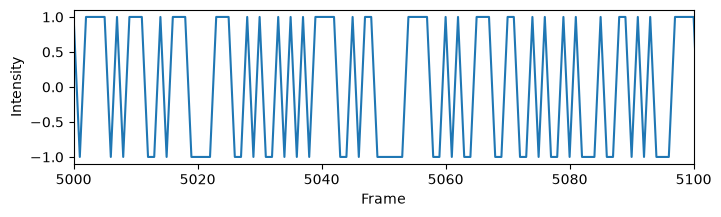

In [15]:
background = np.mean(stimulus_intensity)
stimulus_contrast = (stimulus_intensity - background)/ background
fh, ax = plt.subplots(1, 1, figsize=(8,2))
ax.plot(stimulus_contrast)
ax.set_xlim([5000, 5100])
ax.set_ylabel('Intensity')
ax.set_xlabel('Frame')

Let's look at the spike data - the first thing we should do is figure out what the data type is and, if it's an array, what shape it is

We need to figure out what the dimensions correspond to

In [16]:
print(type(spike_binary))
spike_binary.shape

<class 'numpy.ndarray'>


(48, 9000)

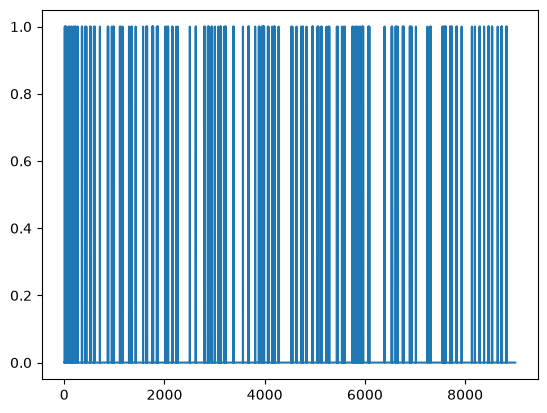

In [18]:
plt.plot(spike_binary[10, :])

Let's plot the spike binary for the cell at index 10

# 2) Examine the stimulus and its statistical properties
Using random noise stimuli has some advantages, which we can see by looking at the statistical properties of the stimulus

 1. The average contrast is 0, and the distribution of contrast is symmetric around 0. This means that you are as likely to see a bright frame as you are a dark frame
2. Within a neuron's **integration time**, the average contrasts presented to the cell are roughly gaussian distributed
3. There are no temporal correlations within the stimulus - meaning that you cannot predict what the next frame will be

Let's look at each of these statisical properties


In [19]:
np.mean(stimulus_contrast)

np.float64(0.0)

### <span style='color:red;'>EXERCISE 2</span>: Examine the distribution of contrast values (5 minutes)
Look up how to plot a histogram using pyplot. And then plot the histogram of contrast values in the stimulus. Be sure to label your axes!

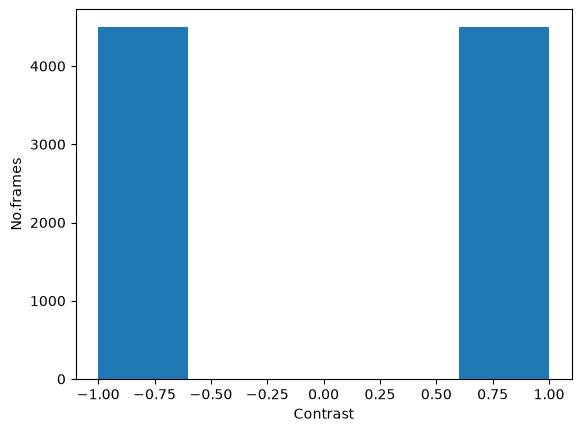

In [31]:
plt.hist(stimulus_contrast, bins=5)
plt.xlabel('Contrast')
plt.ylabel('No.frames')
plt.show()

## Statistics of stimulus snippets
A neuron's response will depend not just on the intensity of the current frame, but all the frames that happened some period of time in the past. This period of time is sometimes called the "integration window" and it's sort of like the cell's memory

Say we expect a cell's memory to be about 25 frames (at 33msec/frame this is about 800 msec into the past). 

Let's consider all of the ~800msec stimulus snippets that were presented to the cells

We are going to collect the stimulus snippets using a **for-loop**. We will start with **pseudo-code** to plan our approach, and then start writing real code

In [35]:
numbers = [2, 5, 1, 6, 23]
cumulative_sum = 0 
for num in numbers:
    print(num)
    cumulative_sum += num
    cumlative_sum = cumulative_sum + num
print(cumulative_sum)

2
5
1
6
23
37


In [45]:
# define a window size, in frames
window_size = 25

# loop over all the frames - except the first window_size
#     for each frame: find the start and stop frames of that snippet 
#     use start/stop frames to index into the stimulus_contrast to get the snippet
#     append the new snippet to a growing list

stim_snippets = []
for frame in range(window_size, len(stimulus_contrast)): 
    start_frame = frame - window_size
    end_frame = frame
    new_stim_snippet = stimulus_contrast[start_frame:end_frame]
    stim_snippets.append(new_stim_snippet)

In [44]:
len(stim_snippets[10])

25

What is the **average** stimulus snippet?

Another useful property of noise stimuli is that there are no correlations in the stimulus, which means that our estimate of what the cell likes will not be biased by structure in the stimulus itself

Let's look at the stimulus cross-correlation with itself (autocorrelation)

A cross correlation shows how two time series are correlated as you shit them in time relative to one another

# 3) Plot spike rasters to see the responses

A common way to look at spike trains is as a raster plot. We plot a vertical tick at every spike time. Let's plot the spike raster for the cell at index 8

### <span style='color:red;'>EXERCISE 3</span>: Plot the spike raster for all of the cells (15 minutes)
Use a for loop to go through the spike responses for each cell and plot a raster. Plot all rasters on a single axis, you can offset the rasters by assiging each one a different y value. For example, if you loop over cell indexes, you can use the cell index as the y value for that cell, so the y values go from 0, 1, 2, ..., 48

# 4) Compute the spike triggered average
A compact description of the stimulus that a cell is excited by is the spike triggered average. Let's compute the STA for one of our neurons.

This is many steps, so let's plan the approach using pseudo-code first

### <span style='color:red;'>EXERCISE 4</span>: Fill in the code to compute the STA (20 minutes)


### <span style='color:red;'>EXERCISE 5</span>: Plot the spike triggered average for this cell (5 minutes)


# 5) Plot the STA for all the cells

define a function, called get_sta(), which takes as the input the stimulus, spike binary, and the window size and returns the sta

Use a for-loop to loop over all 48 cells, and plot each STA in a separate subplot axis of a single, mutipanel figure